# World's largest islands

This dataset `largest-islands.csv` contains information about the 100 largest islands in the world. The unit for the `area` column is km2.

In [1]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'largest-islands.csv'.

# from google.colab import files
# uploaded = files.upload()

In [109]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('largest-islands.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   region     100 non-null    str  
 1   island     100 non-null    str  
 2   area       100 non-null    int64
 3   countries  100 non-null    str  
 4   climate    100 non-null    str  
 5   rank       100 non-null    int64
dtypes: int64(2), str(4)
memory usage: 4.8 KB


### Project Ideas

- What are the 10 largest islands in the tropics?

- What are the largest islands in each `region`?

- Create a line graph with `area` on the y-axis and `rank` on the x-axis. The data should be ordered by `rank`, from largest to smallest.

- What islands are composed of multiple countries?
	- Hint: try `countries.str.contains(",")`

In [85]:
topten = df.query('climate == "tropics"').sort_values(by='area', ascending= False)
topten.head(10)

,region,island,area,countries,climate,rank
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
0,Africa,Madagascar,591896,Madagascar,tropics,4
28,Asia,Sumatra,480793,Indonesia,tropics,6
22,Asia,Sulawesi,188522,Indonesia,tropics,11
21,Asia,Java,129438,Indonesia,tropics,13
80,North America,Cuba,109884,Cuba,tropics,16
26,Asia,Luzon,104688,Philippines,tropics,17
14,Asia,Mindanao,94630,Philippines,tropics,19
73,North America,Hispaniola,76192,"Dominican Republic, Haiti",tropics,23


In [103]:
largest = df.sort_values(by='area', ascending=False).query('area == area.max()')
# Region = largest['island'].iloc[0]
largest['area'].tolist()

Regionslist = df['region'].unique().tolist()
Regionslist
for region in Regionslist:
    print(region)

Africa
Antarctic
Asia
Eurasia
Europe
North America
Oceania
South America


In [121]:
# What are the largest islands in each region?
# Ordena internamente y extrae el último valor (el más grande) de la columna 'island'
resultado_simple = df.sort_values('area').groupby('region')['island'].last().reset_index()

print(resultado_simple)


          region                           island
0         Africa                       Madagascar
1      Antarctic                        Kerguelen
2           Asia                           Borneo
3        Eurasia                         Sakhalin
4         Europe                        Greenland
5  North America                    Baffin Island
6        Oceania                       New Guinea
7  South America  Isla Grande de Tierra del Fuego


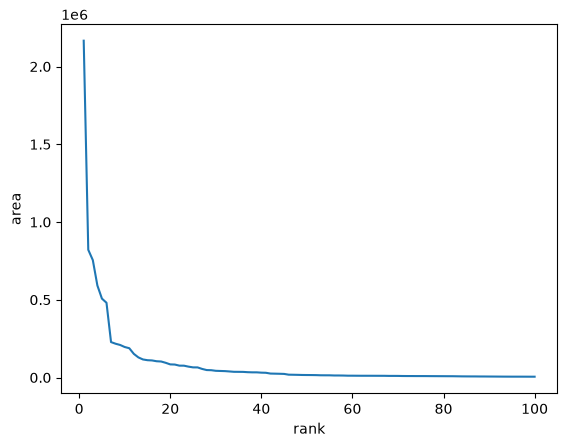

In [129]:
# Create a line graph with `area` on the y-axis and `rank` on the x-axis. The data should be ordered by `rank`, 
# from largest to smallest.
graph = df.sort_values(by='rank', ascending=True)
plt.plot(graph['rank'],graph['area'])
plt.xlabel('rank')
plt.ylabel('area')
plt.show()

In [131]:
# What islands are composed of multiple countries?
df.query('countries.str.contains(",")')
# Hint: try countries.str.contains(",")

,region,island,area,countries,climate,rank
1,Antarctic,Kerguelen,6200,"Antarctic Lands, France",temperate,91
23,Asia,Borneo,755000,"Indonesia, Malaysia, Brunei",tropics,3
45,Europe,Ireland,84421,"Ireland, United Kingdom",temperate,20
50,Europe,Cyprus,9251,"Cyprus, United Kingdom",temperate,76
73,North America,Hispaniola,76192,"Dominican Republic, Haiti",tropics,23
86,Oceania,New Guinea,821400,"Papua New Guinea, Indonesia",tropics,2
98,South America,Isla Grande de Tierra del Fuego,47992,"Chile, Argentina",temperate,28
